# 横磁場イジングモデル：Trotter分解（量子回路）

横磁場イジングモデルの初期状態$\ket{+\cdots+}$からの横磁化$m_x(t)$を、Trotter分解した量子回路で求める。以下ではQiskitで回路を組み、状態ベクトルシミュレータで計算する。手法の一般論は [methods/03_trotter.ipynb](../../methods/03_trotter.ipynb)、模型の定義は [00_model.ipynb](00_model.ipynb) を参照。

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 厳密対角化（src/qmb/operators.py, ed.py）と TFIM の定義（src/qmb/models.py）
from qmb.operators import plus_state
from qmb.ed import ground_state, time_evolve_expectation
from qmb.models import tfim_hamiltonian as hamiltonian, magnetization_x
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# TFIM の Trotter 回路（src/qmb/circuits.py）
#   tfim_op, mx_op : H と M_x を Pauli 演算子の和（SparsePauliOp）で表したもの
#   plus_circuit   : |+...+> を作る回路
#   trotter_step   : Trotter分解の1ステップ（order=1 または 2）
#   mx_trotter     : Trotter分解で m_x(t) を計算
# 実装を見たいときは、Jupyterで関数名の後に ?? を付けて実行する（例: tfim_hamiltonian??）
from qmb.circuits import tfim_op, mx_op, plus_circuit, trotter_step, mx_trotter

## 1. ハミルトニアンの分け方と回路

ハミルトニアンを、中の項がすべて交換する2つのグループに分ける。

\begin{equation}
H = H_{ZZ} + H_X,\quad H_{ZZ} = -J\sum_j Z_jZ_{j+1},\quad H_X = -h\sum_j X_j
\end{equation}

$H_{ZZ}$と$H_X$どうしは交換しない（$[H_{ZZ}, H_X]\neq0$）ので、Trotter分解が必要になる。1次の分解の1ステップは$e^{-iH_X\delta t}e^{-iH_{ZZ}\delta t}$である。

- **ゲートへの変換**

  $H_{ZZ}$の中の項どうし、$H_X$の中の項どうしはそれぞれ交換するので

  \begin{equation}
  e^{-iH_{ZZ}\delta t} = \prod_j e^{iJ\delta t\,Z_jZ_{j+1}} = \prod_j R_{ZZ}(-2J\delta t),\qquad
  e^{-iH_X\delta t} = \prod_j e^{ih\delta t\,X_j} = \prod_j R_X(-2h\delta t)
  \end{equation}

  と、ちょうど分解できる。ここで$R_{ZZ}(\theta) = e^{-i\frac{\theta}{2}Z\otimes Z}$、$R_X(\theta) = e^{-i\frac{\theta}{2}X}$はQiskitの標準ゲートである。

  したがって1ステップ分の回路は「$R_{ZZ}$を隣り合うペアにかける層」と「$R_X$を全サイトにかける層」だけでできる。$R_{ZZ}$は偶数番目のボンドと奇数番目のボンドに分けると、それぞれ並列にかけられる。そのため1ステップの回路の深さはサイト数$n$によらず3層で、ゲート数は$R_{ZZ}$が$n-1$個、$R_X$が$n$個である。これを$r$回繰り返す。

- **初期状態と測定**

  初期状態$\ket{+\cdots+}$は$\ket{0\cdots0}$の全量子ビットにアダマールゲート$H$をかければ作れる。

  $m_x$を測るには、終状態の全量子ビットに再び$H$をかけて$Z$基底で測定する（$H$で$\ket{\pm}\to\ket{0},\ket{1}$と移るため）。結果のビット$b_j\in\{0,1\}$から$X_j = 1-2b_j = \pm1$が得られるので、多数回（ショット数$N_{\mathrm{shot}}$回）測定して平均をとれば$m_x(t)$の推定値になる。統計誤差は$1/\sqrt{N_{\mathrm{shot}}}$程度である。シミュレータでは状態ベクトルから期待値を直接計算できるので、以下では主にそれを使う。

## 2. この模型でのTrotter誤差の特徴

2つのグループの交換子は

\begin{equation}
[H_{ZZ}, H_X] = 2iJh\sum_{j}\left(Y_jZ_{j+1} + Z_jY_{j+1}\right)
\end{equation}

で、ボンドの数（$\approx n$）に比例して大きくなる。一般論の誤差の上界$\frac{t^2}{2r}\|[H_{ZZ}, H_X]\|$より、同じ$\delta t$でも$n$が大きいほどTrotter誤差は大きくなりうる。

> **1次と2次の分解で$m_x$が一致する理由**
>
> 2次の分解を$r$回繰り返すと、隣り合う$e^{-iH_X\delta t/2}$がくっついて
>
> \begin{equation}
> \left(e^{-iH_X\frac{\delta t}{2}}e^{-iH_{ZZ}\delta t}e^{-iH_X\frac{\delta t}{2}}\right)^r
> = e^{iH_X\frac{\delta t}{2}}\left(e^{-iH_X\delta t}e^{-iH_{ZZ}\delta t}\right)^r e^{-iH_X\frac{\delta t}{2}}
> \end{equation}
>
> と、1次の分解の両側に$e^{\pm iH_X\delta t/2}$をつけた形になる。初期状態$\ket{+\cdots+}$は$H_X$の固有状態なので右端は位相がつくだけであり、左端の$e^{iH_X\delta t/2}$は$M_x$と交換する。したがって**$m_x(t)$は1次と2次で完全に同じ値になり、どちらも誤差は$O(\delta t^2)$**である。状態そのもの（忠実度）は1次と2次で異なるが、今回測る$m_x$に限っては1次の分解でも2次の精度が出る。

## 3. $n=2$の手計算

$n=2$（開放境界）の場合を手で計算する。

- **有効1スピンへの帰着**

  [01_exact_diag.ipynb](01_exact_diag.ipynb)の手計算で見たように、$\ket{++}$から出発すると状態は$\{\ket{\phi_+}, \ket{\psi_+}\}$の2次元部分空間から出ない。この部分空間で

  $$
  Z_1Z_2\ket{\phi_+} = \ket{\phi_+},\quad Z_1Z_2\ket{\psi_+} = -\ket{\psi_+},\quad (X_1+X_2)\ket{\phi_+} = 2\ket{\psi_+}
  $$

  なので、$\ket{\phi_+}$を$\ket{0}$、$\ket{\psi_+}$を$\ket{1}$とみなした1つの有効スピンのPauli行列$\sigma$を使うと

  $$
  H_{ZZ} = -J\sigma_z,\quad H_X = -2h\sigma_x,\quad M_x = \sigma_x,\quad \ket{++} = \frac{\ket{\phi_+}+\ket{\psi_+}}{\sqrt{2}} = \ket{+}_{\mathrm{eff}}
  $$

  と書ける。つまり$n=2$の問題は、磁場$(2h, 0, J)$中の1スピンの問題と同じである。

- **Trotter分解の誤差**

  1次のTrotter分解の1ステップ$e^{-iH_X\delta t}e^{-iH_{ZZ}\delta t}$をBCH公式で1つの指数関数にまとめると、$[\sigma_x, \sigma_z] = -2i\sigma_y$より

  $$
  \begin{aligned}
  \tilde{H}
  &= H_{ZZ} + H_X - \frac{i\delta t}{2}[H_X, H_{ZZ}] + O(\delta t^2) \\
  &= -J\sigma_z - 2h\sigma_x - 2Jh\,\delta t\,\sigma_y + O(\delta t^2)
  \end{aligned}
  $$

  となる。Trotter分解の影響は、$O(\delta t)$の大きさの**$y$方向の余分な磁場**として現れる。

  スピンは磁場の方向$\hat{\boldsymbol{n}}$のまわりを角速度$2\tilde{\Omega}$（$\tilde{\Omega}$は磁場の大きさ）で歳差運動する。$x$方向を向いた初期状態から出発すると、回転の公式より

  $$
  m_x(t) = n_x^2 + (1 - n_x^2)\cos(2\tilde{\Omega}t)
  $$

  となり、$m_x$は$n_x^2$と$\tilde{\Omega}$だけで決まる（$\hat{\boldsymbol{n}}\times\hat{\boldsymbol{x}}$の$x$成分が0であるため）。$y$方向の磁場$2Jh\delta t$が加わっても

  $$
  \tilde{\Omega}^2 = J^2 + 4h^2 + O(\delta t^2),\quad n_x^2 = \frac{4h^2}{\tilde{\Omega}^2}
  $$

  と、どちらも$O(\delta t^2)$しか変わらない。よって$m_x(t)$の誤差は$O(\delta t^2)$であり、2節で述べた「1次の分解でも$m_x$は2次の精度」が$n=2$で具体的に確かめられる。また$\delta t\to0$では$n_x^2 = 4h^2/(J^2+4h^2)$、$\tilde{\Omega} = \sqrt{J^2+4h^2}$となり、厳密対角化の手計算の結果に戻る。

## 4. コードで確かめる

Qiskitで回路を組んで計算する。回路を作る関数は `src/qmb/circuits.py` にまとめてあり、ノートブック冒頭で読み込んでいる。Qiskitは量子ビットの並びが厳密対角化で使った`np.kron`と逆順だが、今回扱う$H$と$M_x$は左右反転で変わらないので、そのまま比較できる。

In [3]:
# Trotter分解の1ステップの回路（n=4）
print(trotter_step(4, 1.0, 0.5, 0.1).draw())

                ┌──────────┐            
q_0: ─■─────────┤ Rx(-0.1) ├────────────
      │ZZ(-0.2) └──────────┘┌──────────┐
q_1: ─■──────────■──────────┤ Rx(-0.1) ├
                 │ZZ(-0.2)  ├──────────┤
q_2: ─■──────────■──────────┤ Rx(-0.1) ├
      │ZZ(-0.2) ┌──────────┐└──────────┘
q_3: ─■─────────┤ Rx(-0.1) ├────────────
                └──────────┘            


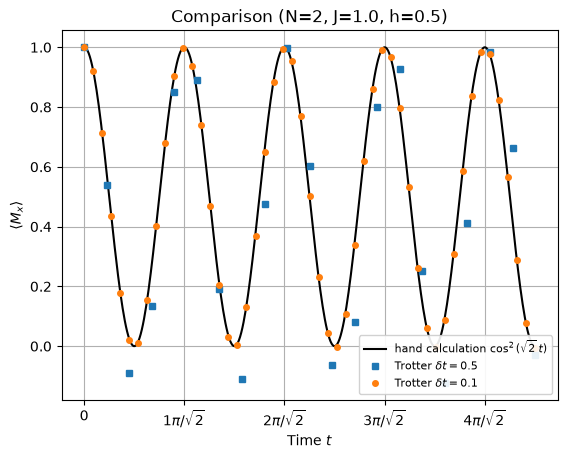

In [4]:
# 例: N=2, J=1, h=0.5（1-4と同じ条件）
N = 2
J = 1.0
h = 0.5
t_max = 10

ts_fine = np.linspace(0, t_max, 400)
T = np.pi / np.sqrt(2)   # 周期
plt.plot(ts_fine, np.cos(np.sqrt(2) * ts_fine)**2, "k-", label=r"hand calculation $\cos^2(\sqrt{2}\,t)$")
for r, mk in [(20, "s"), (100, "o")]:
    ts_r, mx_r = mx_trotter(N, J, h, t_max, r)
    every = max(1, r // 50)
    plt.plot(ts_r[::every], mx_r[::every], mk, ms=4, label=rf"Trotter $\delta t={t_max / r}$")
plt.xticks([k * T for k in range(5)], ["0"] + [rf"${k}\pi/\sqrt{{2}}$" for k in range(1, 5)])
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_x \rangle$")
plt.title(f"Comparison (N={N}, J={J}, h={h})")
plt.legend(loc="lower right", fontsize=8, framealpha=0.9)
plt.grid()
plt.show()

$\delta t = 0.1$では手計算とよく一致し、$\delta t = 0.5$では振動の周期と振幅が少しずれている。これが3節で見たTrotter誤差である。

$n$を大きくしたときの厳密対角化との比較、ステップ数$r$と誤差の関係（1次と2次の比較）、測定のサンプリングによる推定は、[12_quench_dynamics.ipynb](12_quench_dynamics.ipynb)で行う。

---
**前へ**: [02 Jordan-Wigner変換](02_jordan_wigner.ipynb)　｜　**次へ**: [04 VQE](04_vqe.ipynb)